# Diabetes Prediction with Machine Learning

**ICT302 – Advanced Data Analytics for Business · Assessment 2**

**Business problem.** Diabetes is common, costly and often undiagnosed. A health insurer or public-health
agency could use routine survey answers (blood pressure, BMI, general health, age …) to flag people who
should be invited for a blood-glucose test. The goal is a **screening model**: catch as many true diabetics
as possible (high *recall*) while keeping the number of unnecessary referrals reasonable (*precision*).

**Data – CDC BRFSS 2015 Diabetes Health Indicators** (`archive (2)`): answers to the US CDC's 2015
Behavioral Risk Factor Surveillance System telephone survey, cleaned to 21 health-indicator features.
The folder holds three versions of the same survey:

| Part | File | Rows | Target |
|---|---|---|---|
| A (main) | `diabetes_binary_health_indicators_BRFSS2015.csv` | 253,680 | `Diabetes_binary` (0 = no diabetes or pre-diabetes, 1 = diabetes) |
| B | `diabetes_binary_5050split_health_indicators_BRFSS2015.csv` | 70,692 | same, balanced 50/50 |
| C | `diabetes_012_health_indicators_BRFSS2015.csv` | 253,680 | `Diabetes_012` (0 = none, 1 = pre-diabetes, 2 = diabetes) |

**Workflow:** data understanding → cleaning → EDA → train/test split → baseline models → cross-validated
comparison → hyper-parameter tuning → decision-threshold selection → evaluation & interpretation → save model,
followed by two extensions: training on balanced data (B) and three-class prediction (C).

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, recall_score,
                             precision_score, accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, PrecisionRecallDisplay, precision_recall_curve)

%matplotlib inline
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## Part A – Binary diabetes prediction (full dataset)
### 1. Data understanding

In [2]:
DATA_DIR = 'data/'   # contents of the archive (2) folder
df = pd.read_csv(DATA_DIR + 'diabetes_binary_health_indicators_BRFSS2015.csv')
df = df.astype(int)          # every column is stored as float but holds integer codes
print(df.shape)
df.head()

(253680, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0,1,1,1,40,1,0,0,0,0,...,1,0,5,18,15,1,0,9,4,3
1,0,0,0,0,25,1,0,0,1,0,...,0,1,3,0,0,0,0,7,6,1
2,0,1,1,1,28,0,0,0,0,1,...,1,1,5,30,30,1,0,9,4,8
3,0,1,0,1,27,0,0,0,1,1,...,1,0,2,0,0,0,0,11,3,6
4,0,1,1,1,24,0,0,0,1,1,...,1,0,2,3,0,0,0,11,5,4


In [3]:
print('Missing values :', df.isna().sum().sum())
print('Duplicate rows :', df.duplicated().sum())
df.describe().T

Missing values : 0
Duplicate rows : 24206


,count,mean,std,min,25%,50%,75%,max
Diabetes_binary,253680.0,0.139333,0.346294,0.0,0.0,0.0,0.0,1.0
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0


**Observations**

* No missing values; all features are numeric codes (binary flags, ordinal scales such as `GenHlth` 1–5,
  `Age` 1–13 in 5-year bands, `Income` 1–8) plus the counts `BMI`, `MentHlth`, `PhysHlth`.
* ~24k rows are exact duplicates. Because almost every column is a yes/no answer, two different
  respondents can easily give identical answers, so these are kept as genuine observations.
* The target is **imbalanced**: only ~14% of respondents have diabetes (pre-diabetes is coded as 0 in this file). Accuracy would therefore be
  misleading (predicting "no" for everyone already gives 86%), so we evaluate with ROC-AUC, PR-AUC,
  recall, precision and F1.

### 2. Exploratory data analysis

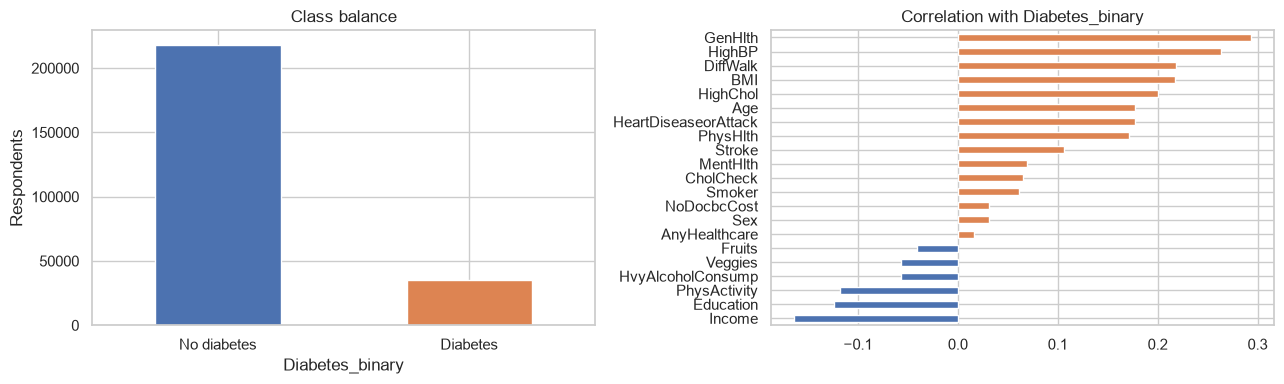

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
df['Diabetes_binary'].map({0: 'No diabetes', 1: 'Diabetes'}).value_counts().plot.bar(ax=ax[0], color=['#4C72B0', '#DD8452'])
ax[0].set_title('Class balance'); ax[0].set_ylabel('Respondents'); ax[0].tick_params(axis='x', rotation=0)
corr = df.corr()['Diabetes_binary'].drop('Diabetes_binary').sort_values()
corr.plot.barh(ax=ax[1], color=np.where(corr > 0, '#DD8452', '#4C72B0'))
ax[1].set_title('Correlation with Diabetes_binary')
plt.tight_layout(); plt.show()

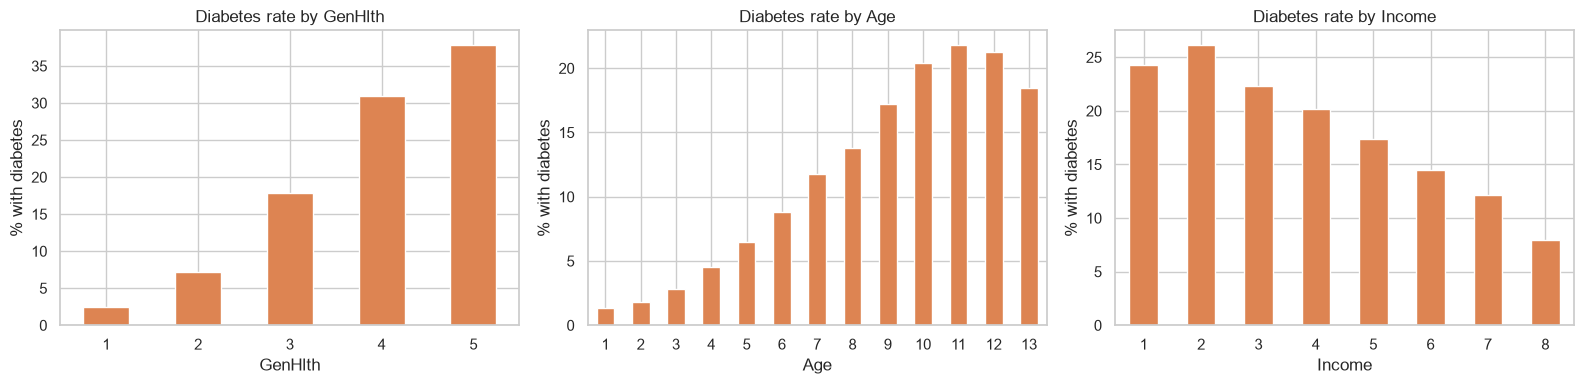

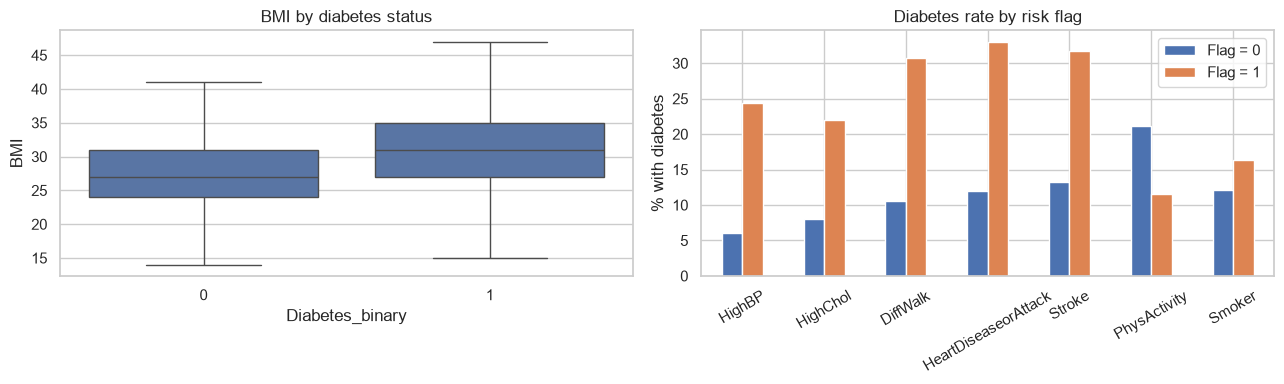

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ['GenHlth', 'Age', 'Income']):
    df.groupby(col)['Diabetes_binary'].mean().mul(100).plot.bar(ax=a, color='#DD8452')
    a.set_ylabel('% with diabetes'); a.set_title(f'Diabetes rate by {col}'); a.tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=df, x='Diabetes_binary', y='BMI', ax=ax[0], showfliers=False)
ax[0].set_title('BMI by diabetes status')
rate = df[['HighBP', 'HighChol', 'DiffWalk', 'HeartDiseaseorAttack', 'Stroke', 'PhysActivity', 'Smoker']] \
    .apply(lambda s: df.groupby(s)['Diabetes_binary'].mean()).T.mul(100)
rate.columns = ['Flag = 0', 'Flag = 1']
rate.plot.bar(ax=ax[1]); ax[1].set_ylabel('% with diabetes'); ax[1].set_title('Diabetes rate by risk flag')
ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout(); plt.show()

**EDA insights**

* The strongest single signals are **general health (`GenHlth`)**, **high blood pressure**, **BMI**,
  **difficulty walking**, **high cholesterol** and **age**. Diabetes prevalence climbs steeply from ~2% for
  "excellent" self-rated health to ~38% for "poor".
* Socio-economic factors matter: diabetes rate falls steadily as **income** and education rise.
* Physical activity is protective (negative correlation).
* Correlations are moderate (max ≈ 0.29), so no single feature predicts diabetes well – a multivariate model is needed.

### 3. Train / test split
A stratified 80/20 split keeps the 14% positive rate in both sets. The test set is held out until final evaluation.

In [6]:
TARGET = 'Diabetes_binary'
X = df.drop(columns=TARGET)
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Train:', X_train.shape, ' positive rate %.3f' % y_train.mean())
print('Test :', X_test.shape, ' positive rate %.3f' % y_test.mean())

Train: (202944, 21)  positive rate 0.139
Test : (50736, 21)  positive rate 0.139


### 4. Candidate models (5-fold cross-validation on the training set)

* **Dummy** – always predicts the majority class (baseline).
* **Logistic Regression** – interpretable linear model; features are standardised.
* **Decision Tree** – simple non-linear model (depth-limited to avoid over-fitting).
* **Random Forest** – bagged ensemble of trees.
* **Histogram Gradient Boosting** – boosted trees, fast on large data.

All models use `class_weight='balanced'` so the minority (diabetic) class is not ignored.

In [7]:
models = {
    'Dummy': DummyClassifier(strategy='most_frequent'),
    'Logistic Regression': Pipeline([('scale', StandardScaler()),
                                     ('clf', LogisticRegression(max_iter=1000, class_weight='balanced'))]),
    'Decision Tree': DecisionTreeClassifier(max_depth=8, min_samples_leaf=50,
                                            class_weight='balanced', random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=20,
                                            class_weight='balanced', n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient Boosting': HistGradientBoostingClassifier(class_weight='balanced', random_state=RANDOM_STATE),
}

scoring = {'roc_auc': 'roc_auc', 'pr_auc': 'average_precision', 'recall': 'recall',
           'precision': 'precision', 'f1': 'f1', 'accuracy': 'accuracy'}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for name, model in models.items():
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    cv_rows.append({'Model': name, **{m: res[f'test_{m}'].mean() for m in scoring},
                    'fit_time_s': res['fit_time'].mean()})
cv_results = pd.DataFrame(cv_rows).set_index('Model').sort_values('roc_auc', ascending=False)
cv_results.round(3)

,roc_auc,pr_auc,recall,precision,f1,accuracy,fit_time_s
Model,,,,,,,
Gradient Boosting,0.830,0.435,0.794,0.307,0.443,0.722,1.587
Random Forest,0.829,0.432,0.779,0.311,0.445,0.729,4.602
Logistic Regression,0.823,0.406,0.766,0.312,0.443,0.732,0.186
Decision Tree,0.817,0.403,0.781,0.297,0.430,0.711,0.324
Dummy,0.500,0.139,0.000,0.000,0.000,0.861,0.025


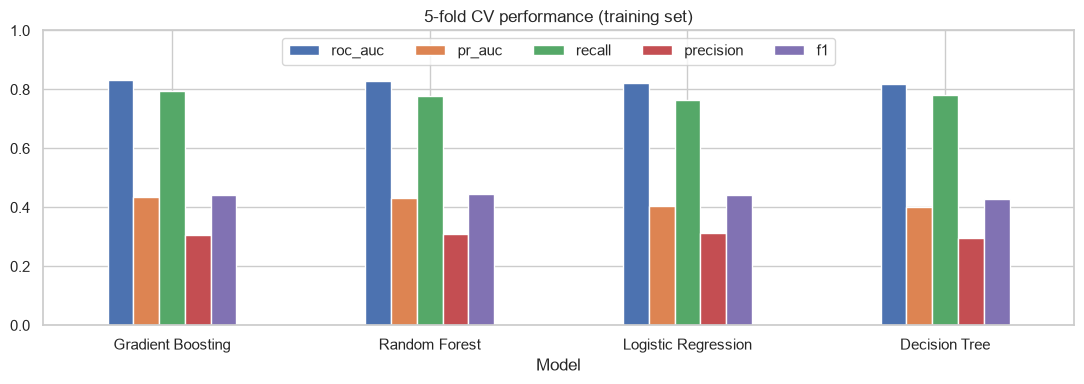

In [8]:
ax = cv_results.drop(index='Dummy')[['roc_auc', 'pr_auc', 'recall', 'precision', 'f1']].plot.bar(figsize=(11, 4))
ax.set_title('5-fold CV performance (training set)'); ax.set_ylim(0, 1); ax.tick_params(axis='x', rotation=0)
ax.legend(ncol=5, loc='upper center'); plt.tight_layout(); plt.show()

Gradient Boosting gives the best ranking ability (ROC-AUC / PR-AUC), with Logistic Regression and
Random Forest close behind; the single Decision Tree is weakest. The dummy model shows why accuracy is
misleading here: ~86% accuracy with 0 recall. Gradient Boosting is taken forward for tuning.

### 5. Hyper-parameter tuning (Gradient Boosting)

In [9]:
param_dist = {
    'learning_rate': [0.03, 0.05, 0.1, 0.2],
    'max_iter': [200, 300, 500],
    'max_leaf_nodes': [15, 31, 63],
    'min_samples_leaf': [20, 50, 100, 200],
    'l2_regularization': [0.0, 0.1, 1.0],
}
search = RandomizedSearchCV(
    HistGradientBoostingClassifier(class_weight='balanced', early_stopping=True, random_state=RANDOM_STATE),
    param_dist, n_iter=20, scoring='roc_auc', cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
    n_jobs=-1, random_state=RANDOM_STATE)
search.fit(X_train, y_train)
print('Best CV ROC-AUC: %.4f' % search.best_score_)
print('Best parameters:', search.best_params_)
best_model = search.best_estimator_

Best CV ROC-AUC: 0.8304
Best parameters: {'min_samples_leaf': 200, 'max_leaf_nodes': 15, 'max_iter': 200, 'learning_rate': 0.05, 'l2_regularization': 0.0}


### 6. Choosing the decision threshold

A default threshold of 0.5 is arbitrary. For screening we choose the threshold on **out-of-fold training
predictions** (never on the test set) that maximises F1, and also report a high-recall alternative
(recall ≥ 80%) that a public-health programme might prefer.

In [10]:
from sklearn.model_selection import cross_val_predict
oof = cross_val_predict(best_model, X_train, y_train, cv=StratifiedKFold(3, shuffle=True, random_state=RANDOM_STATE),
                        method='predict_proba', n_jobs=-1)[:, 1]
prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
thr_f1 = thr[f1s.argmax()]
thr_recall80 = thr[np.where(rec[:-1] >= 0.80)[0].max()]
print(f'Threshold maximising F1     : {thr_f1:.3f}')
print(f'Threshold for recall >= 80% : {thr_recall80:.3f}')

Threshold maximising F1     : 0.659
Threshold for recall >= 80% : 0.492


### 7. Final evaluation on the held-out test set

In [11]:
proba_test = best_model.predict_proba(X_test)[:, 1]

def summarise(y_true, proba, threshold):
    pred = (proba >= threshold).astype(int)
    return {'threshold': threshold, 'ROC-AUC': roc_auc_score(y_true, proba),
            'PR-AUC': average_precision_score(y_true, proba), 'Accuracy': accuracy_score(y_true, pred),
            'Recall': recall_score(y_true, pred), 'Precision': precision_score(y_true, pred),
            'F1': f1_score(y_true, pred)}

test_results = pd.DataFrame({
    'Default (0.5)': summarise(y_test, proba_test, 0.5),
    'Max-F1': summarise(y_test, proba_test, thr_f1),
    'Recall >= 80%': summarise(y_test, proba_test, thr_recall80),
}).T
test_results.round(3)

,threshold,ROC-AUC,PR-AUC,Accuracy,Recall,Precision,F1
Default (0.5),0.500,0.827,0.423,0.720,0.795,0.306,0.442
Max-F1,0.659,0.827,0.423,0.808,0.602,0.381,0.466
Recall >= 80%,0.492,0.827,0.423,0.714,0.803,0.302,0.439


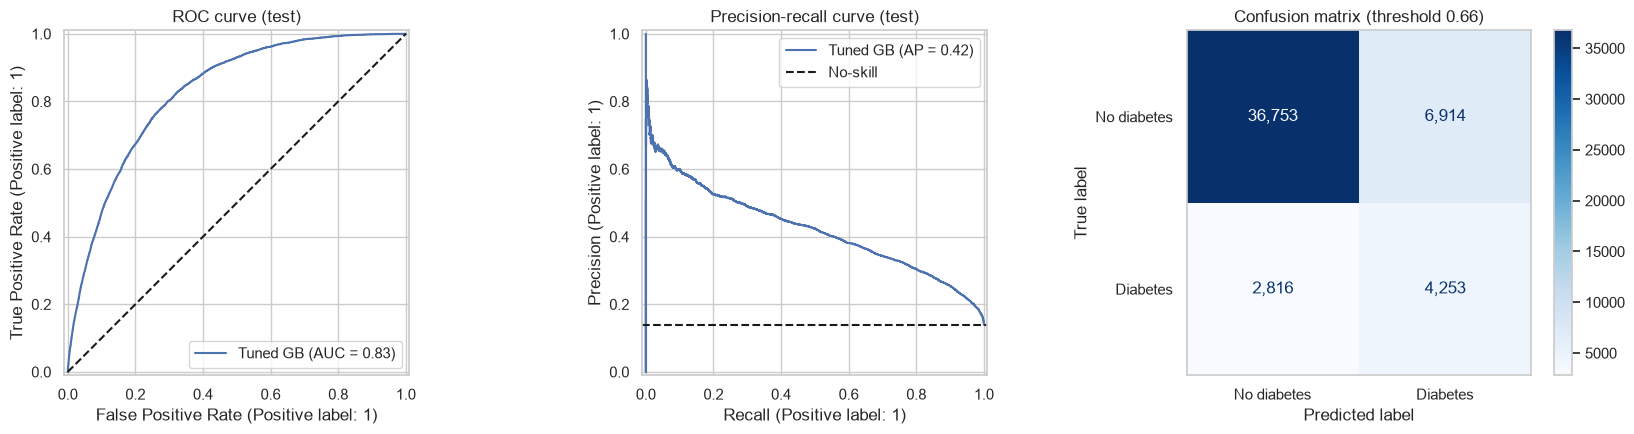

              precision    recall  f1-score   support

 No diabetes       0.93      0.84      0.88     43667
    Diabetes       0.38      0.60      0.47      7069

    accuracy                           0.81     50736
   macro avg       0.65      0.72      0.67     50736
weighted avg       0.85      0.81      0.83     50736



In [12]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
RocCurveDisplay.from_predictions(y_test, proba_test, ax=ax[0], name='Tuned GB'); ax[0].plot([0, 1], [0, 1], 'k--')
ax[0].set_title('ROC curve (test)')
PrecisionRecallDisplay.from_predictions(y_test, proba_test, ax=ax[1], name='Tuned GB')
ax[1].axhline(y_test.mean(), ls='--', c='k', label='No-skill'); ax[1].legend(); ax[1].set_title('Precision-recall curve (test)')
ConfusionMatrixDisplay.from_predictions(y_test, (proba_test >= thr_f1).astype(int), ax=ax[2], cmap='Blues',
                                        display_labels=['No diabetes', 'Diabetes'], values_format=',')
ax[2].set_title(f'Confusion matrix (threshold {thr_f1:.2f})'); ax[2].grid(False)
plt.tight_layout(); plt.show()
print(classification_report(y_test, (proba_test >= thr_f1).astype(int), target_names=['No diabetes', 'Diabetes']))

### 8. Model interpretation – permutation importance
How much does test ROC-AUC drop when each feature is randomly shuffled?

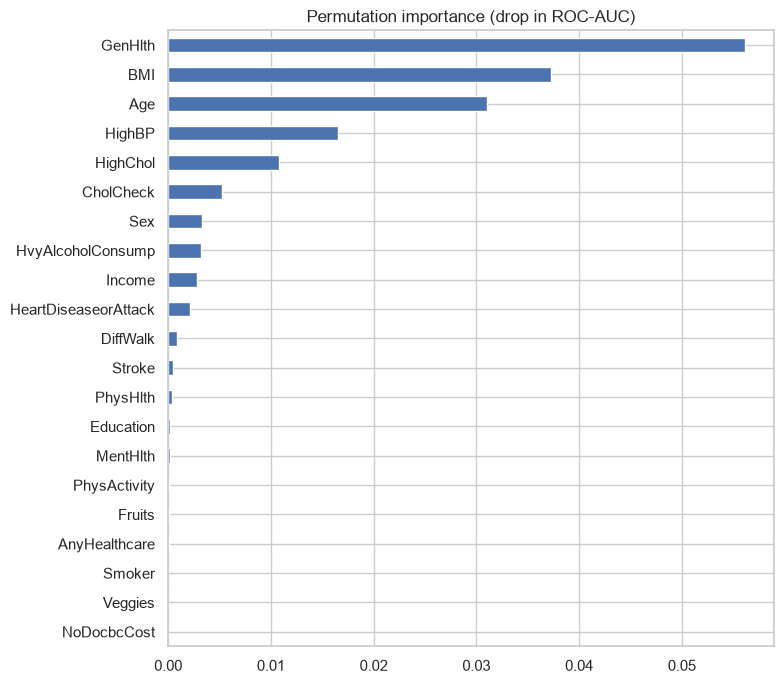

GenHlth              0.0562
BMI                  0.0372
Age                  0.0311
HighBP               0.0166
HighChol             0.0108
CholCheck            0.0053
Sex                  0.0033
HvyAlcoholConsump    0.0031
dtype: float64

In [13]:
sample = X_test.sample(20000, random_state=RANDOM_STATE)
pi = permutation_importance(best_model, sample, y_test.loc[sample.index], scoring='roc_auc',
                            n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(pi.importances_mean, index=X.columns).sort_values()
importance.plot.barh(figsize=(8, 7), color='#4C72B0')
plt.title('Permutation importance (drop in ROC-AUC)'); plt.tight_layout(); plt.show()
importance.sort_values(ascending=False).head(8).round(4)

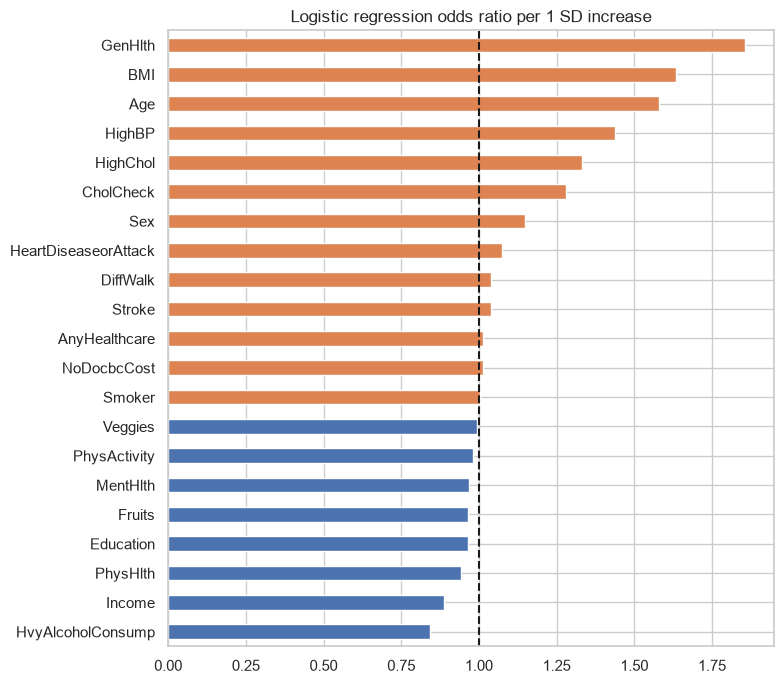

In [14]:
# Logistic regression odds ratios give a directional, easy-to-explain view of the same drivers
lr = models['Logistic Regression'].fit(X_train, y_train)
odds = pd.Series(np.exp(lr.named_steps['clf'].coef_[0]), index=X.columns).sort_values()
odds.plot.barh(figsize=(8, 7), color=np.where(odds > 1, '#DD8452', '#4C72B0'))
plt.axvline(1, c='k', ls='--'); plt.title('Logistic regression odds ratio per 1 SD increase'); plt.tight_layout(); plt.show()

### 9. Save the model

In [15]:
import os
os.makedirs('models', exist_ok=True)
joblib.dump({'model': best_model, 'threshold': float(thr_f1), 'features': list(X.columns)},
            'models/brfss_diabetes_gb.joblib')

# Example: scoring a new respondent
bundle = joblib.load('models/brfss_diabetes_gb.joblib')
new_person = X_test.iloc[[0]]
p = bundle['model'].predict_proba(new_person)[0, 1]
print(f'Predicted risk {p:.1%} -> {"refer for test" if p >= bundle["threshold"] else "no referral"}')

Predicted risk 49.5% -> no referral


## Part B – Training on the balanced 50/50 file

`diabetes_binary_5050split…csv` contains **all 35,346 diabetics** plus an equal random sample of non-diabetics
from the same survey. Balanced data is a common alternative to class weighting. Because its rows are a
subset of Part A's data, it is evaluated with its own cross-validation rather than on Part A's test set
(which would leak training rows).

In [16]:
bal = pd.read_csv(DATA_DIR + 'diabetes_binary_5050split_health_indicators_BRFSS2015.csv').astype(int)
Xb, yb = bal.drop(columns=TARGET), bal[TARGET]
print(bal.shape, ' positive rate %.2f' % yb.mean())

bal_models = {
    'Logistic Regression': Pipeline([('scale', StandardScaler()), ('clf', LogisticRegression(max_iter=1000))]),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=14, min_samples_leaf=20,
                                            n_jobs=-1, random_state=RANDOM_STATE),
    'Gradient Boosting (tuned params)': HistGradientBoostingClassifier(**search.best_params_, random_state=RANDOM_STATE),
}
rows = []
for name, m in bal_models.items():
    r = cross_validate(m, Xb, yb, cv=cv, scoring=scoring)
    rows.append({'Model': name, **{k: r[f'test_{k}'].mean() for k in scoring}})
bal_cv = pd.DataFrame(rows).set_index('Model')
bal_cv.round(3)

(70692, 22)  positive rate 0.50


,roc_auc,pr_auc,recall,precision,f1,accuracy
Model,,,,,,
Logistic Regression,0.825,0.795,0.767,0.739,0.753,0.748
Random Forest,0.828,0.803,0.794,0.731,0.761,0.750
Gradient Boosting (tuned params),0.831,0.805,0.799,0.732,0.764,0.753


**Interpretation.** ROC-AUC is almost unchanged from Part A, because AUC does not depend on how common the
positive class is. Accuracy, precision and F1 look much higher, but only because half the people in
this file are diabetic. In a real population where about 14% are diabetic, precision would fall back to Part A's levels.
**Lesson for the business:** report metrics at the prevalence where the model will actually be used. Class weighting
on the full data (Part A) achieves the same ranking ability while keeping all 218k non-diabetic records.

## Part C – Three-class prediction: none / pre-diabetes / diabetes

Pre-diabetes is the stage where lifestyle intervention is most effective, so separating it would be valuable.
It is also very rare (1.8% of respondents).

In [17]:
multi = pd.read_csv(DATA_DIR + 'diabetes_012_health_indicators_BRFSS2015.csv').astype(int)
print(multi['Diabetes_012'].value_counts(normalize=True).rename({0: 'None', 1: 'Pre-diabetes', 2: 'Diabetes'}).round(3))

Xm, ym = multi.drop(columns='Diabetes_012'), multi['Diabetes_012']
# same random_state and stratification on the same rows -> identical train/test rows as Part A
Xm_train, Xm_test, ym_train, ym_test = train_test_split(Xm, ym, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

gb_multi = HistGradientBoostingClassifier(**search.best_params_, class_weight='balanced', random_state=RANDOM_STATE)
gb_multi.fit(Xm_train, ym_train)
pm = gb_multi.predict_proba(Xm_test)
pred_m = pm.argmax(axis=1)
labels = ['None', 'Pre-diabetes', 'Diabetes']
print('Macro ROC-AUC (one-vs-rest): %.3f' % roc_auc_score(ym_test, pm, multi_class='ovr', average='macro'))
print('Macro F1: %.3f' % f1_score(ym_test, pred_m, average='macro'))
print(classification_report(ym_test, pred_m, target_names=labels))

Diabetes_012
None            0.842
Diabetes        0.139
Pre-diabetes    0.018
Name: proportion, dtype: float64


Macro ROC-AUC (one-vs-rest): 0.776
Macro F1: 0.422
              precision    recall  f1-score   support

        None       0.96      0.63      0.76     42735
Pre-diabetes       0.03      0.35      0.06       932
    Diabetes       0.35      0.62      0.45      7069

    accuracy                           0.62     50736
   macro avg       0.45      0.53      0.42     50736
weighted avg       0.85      0.62      0.70     50736



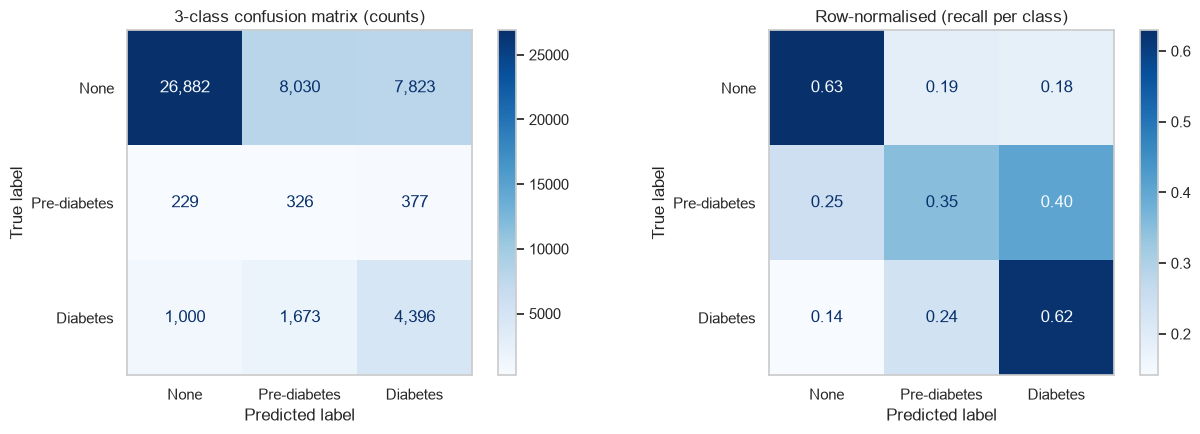

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
ConfusionMatrixDisplay.from_predictions(ym_test, pred_m, display_labels=labels, cmap='Blues', values_format=',', ax=ax[0])
ax[0].set_title('3-class confusion matrix (counts)'); ax[0].grid(False)
ConfusionMatrixDisplay.from_predictions(ym_test, pred_m, display_labels=labels, cmap='Blues', normalize='true',
                                        values_format='.2f', ax=ax[1])
ax[1].set_title('Row-normalised (recall per class)'); ax[1].grid(False)
plt.tight_layout(); plt.show()
joblib.dump(gb_multi, 'models/brfss_diabetes_012_gb.joblib');

**Interpretation.** Macro ROC-AUC is 0.776 and macro F1 is 0.42. The model separates "none" from "diabetes"
about as well as the binary model (diabetes recall 62%), but **pre-diabetes cannot be identified reliably**: class weighting
makes the model flag it often (recall 35%), yet only **3% of those flags are correct**. Its survey profile sits between
the other two classes, and it has only ~4.6k examples. Survey indicators alone cannot separate pre-diabetes. In practice the
binary risk score from Part A is more useful, with anyone flagged then given a blood test to tell pre-diabetes from diabetes.

## 10. Conclusions & business recommendations

* **Survey data alone can screen for diabetes reasonably well.** The tuned Gradient Boosting model reaches a
  **test ROC-AUC of 0.827** (PR-AUC 0.42 vs. a no-skill baseline of 0.14) on 50,736 unseen respondents.
  All four real models land within 0.817–0.830 CV ROC-AUC, so even interpretable logistic regression captures most
  of the signal. It is not a diagnostic test: positives should be referred for an HbA1c check.
* **The threshold is a business decision.**
  * *Max-F1 threshold (0.66):* recall 60%, precision 38%, accuracy 81%. Fewer, better-targeted referrals.
  * *High-recall threshold (0.49):* recall 80%, precision 30%. Catches 4 in 5 diabetics, but about 2 of every 3
    referrals are negative. Preferable when a missed diagnosis costs much more than a test.
* **Key risk drivers:** permutation importance ranks **self-rated general health, BMI, age, high blood pressure
  and high cholesterol** as the top predictors. The EDA also shows higher prevalence with lower income or education
  and with physical inactivity. These are cheap to collect, so a short questionnaire could be deployed through insurers,
  GPs or online health checks to target outreach.
* **Balanced data (Part B) does not improve the model.** ROC-AUC is 0.831 vs. 0.830. The higher precision and accuracy
  (73% / 75%) come only from the artificial 50% prevalence, so stakeholders must see metrics at real-world prevalence.
* **Pre-diabetes (Part C) cannot be singled out from survey answers** (precision 3%). A two-step process, survey
  screening followed by a blood test, is the realistic design.

**Limitations:** the data are self-reported (recall bias; under-diagnosis means some "0" labels are really
undiagnosed diabetics); they come from 2015 US adults and may not transfer to other populations or years; the
features are coarse (mostly yes/no, age in 5-year bands); and results were not checked for fairness across groups.
**Future work:** calibrate probabilities, check performance by sex, age and income group, use SHAP to explain
individual predictions, set a cost-based threshold, and validate on newer BRFSS years.